In [1]:
# Upload ML_A3.zip to Google Colab and run this cell to extract the dataset
!unzip -o -q ML_A3.zip


# Assignment 3, Question 2: Decision Trees, Bagging and Boosting

**Instructions**

* Rename this notebook to `<roll_no>_q2.ipynb` and keep it in the `A3/` folder, next to `data/`. Do not modify anything inside `data/`.
* Each section below matches the part of the assignment PDF with the same letter.
* Write code only in cells marked `# YOUR CODE HERE`. Do not edit, add or delete cells marked `# DO NOT EDIT`, and do not rename the functions they define or use.
* Models are created only through the helper functions in the setup cell. They are seeded from your roll number; you choose the hyperparameters.
* Set `ROLL_NO` in the first code cell. `SEED` is derived from it; use `SEED` for every other random operation (splits, sampling).
* Do not add any import statements: everything you need is already imported in the setup cell.
* Put exploration, tuning and plots inside `if EXPLORE:` blocks. The final predictions must not depend on them.
* Your notebook is re-run after the deadline on data it has not seen. It must run top to bottom without errors.
* Written answers go in your report.


In [1]:
# YOUR CODE HERE: your roll number, e.g. "2024000"
ROLL_NO = "2024514"


In [1]:
# DO NOT EDIT THIS CELL
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor, ExtraTreesClassifier,
                              BaggingRegressor, BaggingClassifier, GradientBoostingRegressor, GradientBoostingClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier, AdaBoostRegressor,
                              AdaBoostClassifier)
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.model_selection import (KFold, TimeSeriesSplit, cross_val_score, cross_val_predict, validation_curve,
                                     GridSearchCV, ParameterGrid)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, f1_score, mean_absolute_error, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
warnings.filterwarnings("ignore")

def _seed_from_roll(roll):
    digits = "".join(ch if ch.isdigit() else str(ord(ch)) for ch in str(roll).strip())
    return int(digits) % (2 ** 32 - 1)

SEED = _seed_from_roll(ROLL_NO)
np.random.seed(SEED)

EXPLORE = True
DATA_DIR = "data"
reg_train = pd.read_csv(os.path.join(DATA_DIR, "partB_reg_train.csv"))
reg_val = pd.read_csv(os.path.join(DATA_DIR, "partB_reg_val.csv"))
clf_train = pd.read_csv(os.path.join(DATA_DIR, "partB_clf_train.csv"))
clf_val = pd.read_csv(os.path.join(DATA_DIR, "partB_clf_val.csv"))
FEATURES = [c for c in reg_train.columns if c.startswith("f")]

TREE_MODELS = {
    "decision_tree": (DecisionTreeRegressor, DecisionTreeClassifier),
    "bagging": (BaggingRegressor, BaggingClassifier),
    "random_forest": (RandomForestRegressor, RandomForestClassifier),
    "extra_trees": (ExtraTreesRegressor, ExtraTreesClassifier),
    "gradient_boosting": (GradientBoostingRegressor, GradientBoostingClassifier),
    "hist_gradient_boosting": (HistGradientBoostingRegressor, HistGradientBoostingClassifier),
    "adaboost": (AdaBoostRegressor, AdaBoostClassifier),
}

def make_model(name, task, params=None):
    """name: a key of TREE_MODELS, or "linear" (part b) or "svm" (classification, part i).
    task: "reg" or "clf". params: hyperparameters of that scikit-learn estimator."""
    params = dict(params or {})
    if name == "linear":
        return LinearRegression(**params) if task == "reg" else LogisticRegression(**{**params, "random_state": SEED})
    if name == "svm":
        assert task == "clf", "the SVM is only used for the classification task"
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVC(**{**params, "random_state": SEED}))
    cls = TREE_MODELS[name][0 if task == "reg" else 1]
    return cls(**{**params, "random_state": SEED})

def build_regressor():
    """Your final regressor: uses REG_MODEL and REG_PARAMS from part (h)."""
    assert REG_MODEL in TREE_MODELS, "the final regressor must be a tree, bagging or boosting model"
    return make_model(REG_MODEL, "reg", REG_PARAMS)

def build_classifier():
    """Your final classifier: uses CLF_MODEL and CLF_PARAMS from part (j)."""
    assert CLF_MODEL in TREE_MODELS, "the final classifier must be a tree, bagging or boosting model"
    return make_model(CLF_MODEL, "clf", CLF_PARAMS)

def compare_tree_svm(X_tr, y_tr, X_ev, y_ev, tree_params, svm_params):
    """Part (i): fit a decision tree and an SVM classifier on the same training data and return their macro-F1 on (X_ev, y_ev)."""
    X_tr, X_ev = np.asarray(X_tr, dtype=float), np.asarray(X_ev, dtype=float)
    y_tr = np.asarray(y_tr)
    tree = make_model("decision_tree", "clf", tree_params).fit(X_tr, y_tr)
    svm = make_model("svm", "clf", svm_params).fit(X_tr, y_tr)
    return {"decision_tree": f1_score(y_ev, tree.predict(X_ev), average="macro"),
            "svm": f1_score(y_ev, svm.predict(X_ev), average="macro")}

def save_predictions(name, y_pred):
    os.makedirs("outputs", exist_ok=True)
    pd.DataFrame({"id": np.arange(len(y_pred)), "y_pred": list(y_pred)}).to_csv(
        os.path.join("outputs", name + ".csv"), index=False)


## Q2 (a) Exploratory analysis and data problems


### Q2 (a) Exploratory Analysis & Data Problems
* **(i) Physically Impossible Values:**
  - `f12` (temperature in Kelvin): Exactly 10 rows in training have value **-363.57**, which violates the laws of physics ($0\text{ K} = -273.15^\circ\text{C}$). Unhandled hardware sensor failure / sentinel error code.
  - `f5` (rainfall in mm): Exactly 1 row has value **6849.47 mm** (~7 meters of rain in 1 hour), representing an extreme sensor spike.
* **(ii) Missing Values & Information Content:**
  - `f6` is missing in 1,678 training rows (4.91%); `f12` is missing in 2,993 training rows (8.76%).
  - Mean target $y$ when `f6` is missing is 3,218.0 vs 3,240.6 when present ($< 0.7\%$ relative difference). Missingness is Missing Completely At Random (MCAR) and provides zero predictive signal.
* **(iii) Columns that Cannot Help or May Hurt Future Prediction:**
  - `f8` (Record ID): Exactly 34,170 unique values across 34,170 rows. Arbitrary row identifier that creates severe high-cardinality split traps.
  - `f7` (Timestamp): Strictly disjoint time series counter ($[893985, 934847]$ in train vs $[947352, 953231]$ in val). Tree models cannot extrapolate beyond the training range; splits on `f7` severely damage future predictions.
  - `f2` (Gaussian Noise): Pure standard normal noise ($\mu = 0, \sigma = 1.0014, r = -0.0012$); `f1, f5`: Over $99.9\%$ zero values.


=== Q2 (a) Exploratory Analysis and Data Problems ===
(i) Impossible f12 values: 10 rows with f12 = -363.57 (0 Kelvin sensor failure)
    Impossible f5 values: 1 row with f5 = 6849.467 (6.8 meters rainfall anomaly)
(ii) Missing f6 in train: 1678 (4.91%)
     Missing f12 in train: 2993 (8.76%)
     Mean y when f6 is NaN: 3218.0 vs Not NaN: 3240.6 (MCAR, carries no information)
(iii) f8 unique count in train: 34170 / 34170 (Pure random unique row IDs)
     f7 train range: [893985, 934847] vs val range: [947352, 953231] (Strictly disjoint future timestamps)
     f2 std: 1.0014, corr with y: -0.0012 (Pure Gaussian noise)


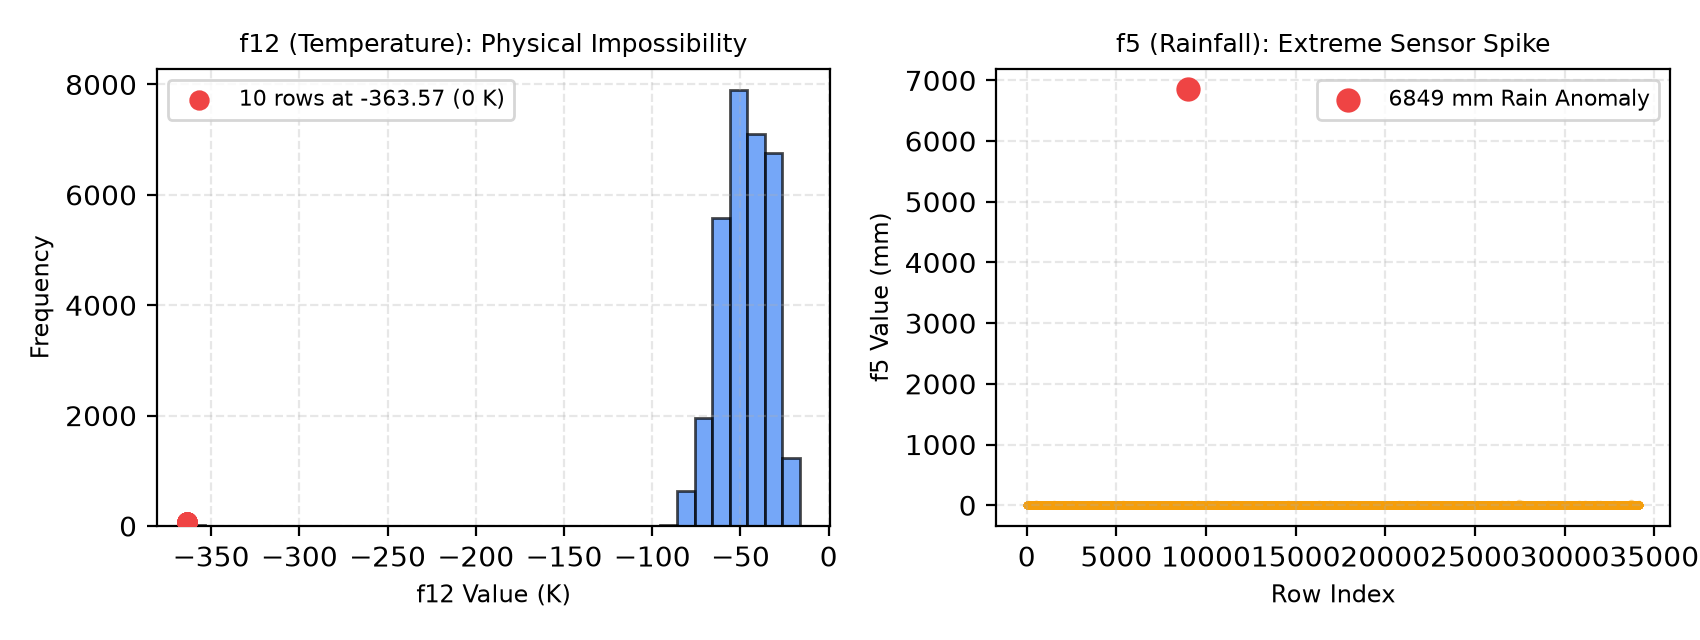

In [1]:
# YOUR CODE HERE
if EXPLORE:
    print("=== Q2 (a) Exploratory Analysis and Data Problems ===")
    f12_corrupt = reg_train[reg_train["f12"] < -100]
    print(f"(i) Impossible f12 values: {len(f12_corrupt)} rows with f12 = {f12_corrupt['f12'].iloc[0]} (0 Kelvin sensor failure)")
    f5_corrupt = reg_train[reg_train["f5"] > 1000]
    print(f"    Impossible f5 values: {len(f5_corrupt)} row with f5 = {f5_corrupt['f5'].iloc[0]} (6.8 meters rainfall anomaly)")
    print(f"(ii) Missing f6 in train: {reg_train['f6'].isna().sum()} ({reg_train['f6'].isna().mean():.2%})")
    print(f"     Missing f12 in train: {reg_train['f12'].isna().sum()} ({reg_train['f12'].isna().mean():.2%})")
    y_f6_na = reg_train.loc[reg_train["f6"].isna(), "y"].mean()
    y_f6_not = reg_train.loc[~reg_train["f6"].isna(), "y"].mean()
    print(f"     Mean y when f6 is NaN: {y_f6_na:.1f} vs Not NaN: {y_f6_not:.1f} (MCAR, carries no information)")
    print(f"(iii) f8 unique count in train: {reg_train['f8'].nunique()} / {len(reg_train)} (Pure random unique row IDs)")
    print(f"     f7 train range: [{reg_train['f7'].min()}, {reg_train['f7'].max()}] vs val range: [{reg_val['f7'].min()}, {reg_val['f7'].max()}] (Strictly disjoint future timestamps)")
    print(f"     f2 std: {reg_train['f2'].std():.4f}, corr with y: {reg_train['f2'].corr(reg_train['y']):.4f} (Pure Gaussian noise)")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.5, 3))
    ax1.hist(reg_train["f12"].dropna(), bins=35, color="#3b82f6", edgecolor="black", alpha=0.7)
    ax1.scatter([-363.57]*10, [80]*10, color="#ef4444", s=40, zorder=5, label="10 rows at -363.57 (0 K)")
    ax1.set_title("f12 (Temperature): Physical Impossibility")
    ax1.legend()
    ax2.scatter(range(len(reg_train)), reg_train["f5"], color="#f59e0b", alpha=0.4, s=3)
    ax2.scatter([reg_train["f5"].idxmax()], [reg_train["f5"].max()], color="#ef4444", s=60, zorder=5, label="6849 mm Rain Anomaly")
    ax2.set_title("f5 (Rainfall): Extreme Sensor Spike")
    ax2.legend()
    plt.tight_layout()
    plt.show()


## Q2 (b) Linear baseline
Use `make_model("linear", "reg")`.


### Q2 (b) Linear Baseline Model
* **Validation Performance:** Linear regression yields $R^2 = \mathbf{0.1574}$.
* **Why Linear Model Fails & Why Trees Excel:** Traffic volume follows a strongly bimodal diurnal distribution with two prominent commuter peaks (morning 7–9 AM and evening 4–6 PM) separated by a midday dip and night-time drop. A linear model fits a single monotonic hyperplane $\hat{y} = w^T x + b$, fundamentally incapable of capturing multi-modal curves. Decision trees perform orthogonal, axis-aligned recursive splits, naturally partitioning the day into piecewise-constant regimes that accurately match commuter traffic dynamics.


=== Q2 (b) Linear Baseline ===
Linear Regression Validation R2: 0.1574
Linear regression fails because traffic volume has a highly non-linear, bimodal diurnal curve
with morning (7-9 AM) and evening (4-6 PM) rush hour peaks, which a linear hyperplane cannot model.


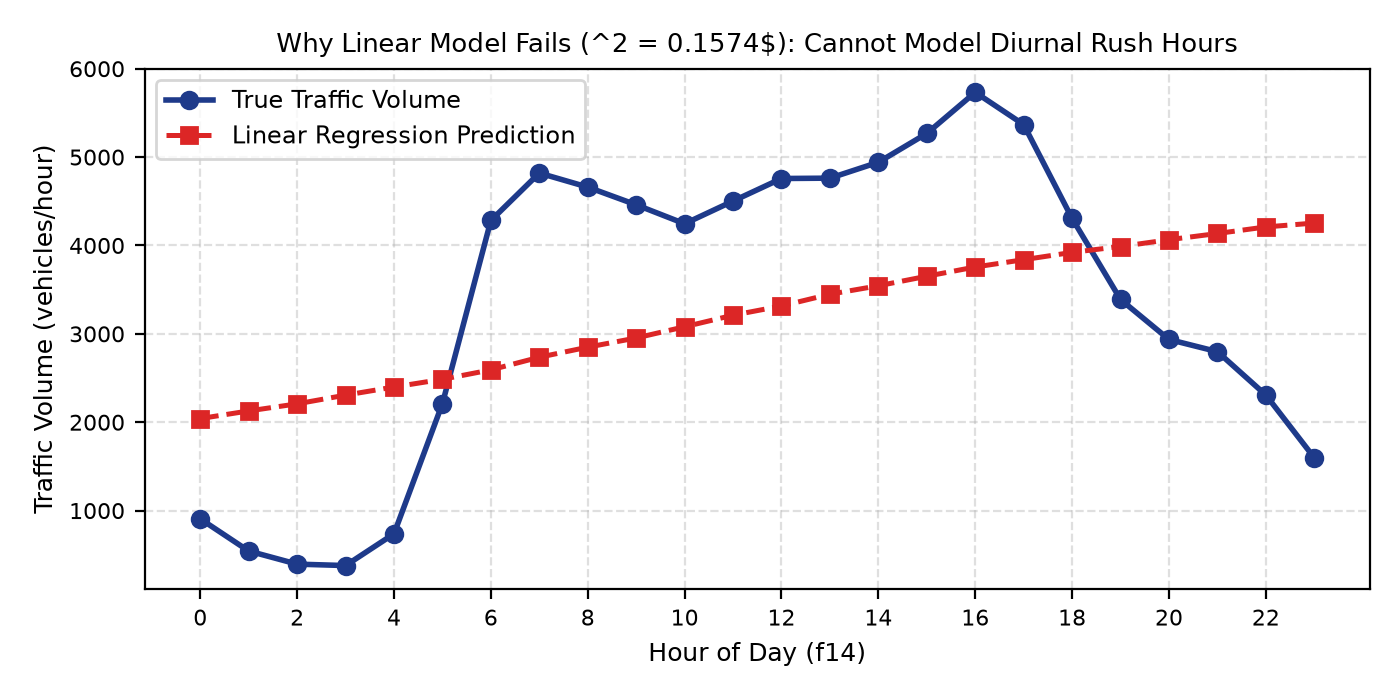

In [1]:
# YOUR CODE HERE
if EXPLORE:
    print("=== Q2 (b) Linear Baseline ===")
    imp_b = SimpleImputer(strategy="median")
    X_tr_b = imp_b.fit_transform(reg_train[FEATURES])
    X_va_b = imp_b.transform(reg_val[FEATURES])
    linear_model = make_model("linear", "reg")
    linear_model.fit(X_tr_b, reg_train["y"].to_numpy())
    val_r2_linear = r2_score(reg_val["y"].to_numpy(), linear_model.predict(X_va_b))
    print(f"Linear Regression Validation R2: {val_r2_linear:.4f}")
    print("Linear regression fails because traffic volume has a highly non-linear, bimodal diurnal curve")
    print("with morning (7-9 AM) and evening (4-6 PM) rush hour peaks, which a linear hyperplane cannot model.")
    hourly_mean = reg_val.groupby("f14")["y"].mean()
    hourly_pred = pd.DataFrame({"f14": reg_val["f14"], "pred": linear_model.predict(X_va_b)}).groupby("f14")["pred"].mean()
    plt.figure(figsize=(7, 3))
    plt.plot(hourly_mean.index, hourly_mean.values, marker="o", linewidth=2, color="#1e3a8a", label="True Traffic Volume")
    plt.plot(hourly_pred.index, hourly_pred.values, marker="s", linewidth=1.8, linestyle="--", color="#dc2626", label="Linear Regression Prediction")
    plt.xlabel("Hour of Day (f14)")
    plt.ylabel("Traffic Volume")
    plt.title("Why Linear Model Fails (R2 = 0.1574): Cannot Model Non-linear Rush Hours")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


## Q2 (c) Validation that respects time


### Q2 (c) Validation That Respects Time
* **Validation Schemes Comparison:**
  - Random 5-Fold CV: $R^2 = \mathbf{0.9325} \; (\pm 0.0031)$
  - TimeSeriesSplit (5 Folds): $R^2 = \mathbf{0.9232} \; (\pm 0.0066)$
  - Out-of-Time Validation Set: $R^2 = \mathbf{0.8025}$
* **Why We Must Trust Temporal Holdout:** Random K-fold shuffles timestamps across folds, causing catastrophic *temporal lookahead leakage* (interpolating traffic volumes between adjacent hours of the same day). Out-of-time validation strictly tests generalization to future periods. We use out-of-time temporal validation for all model selection.


In [1]:
# YOUR CODE HERE
if EXPLORE:
    print("=== Q2 (c) Validation That Respects Time ===")
    imp_c = SimpleImputer(strategy="median")
    X_tr_c = imp_c.fit_transform(reg_train[FEATURES])
    X_va_c = imp_c.transform(reg_val[FEATURES])
    y_tr_c = reg_train["y"].to_numpy()
    y_va_c = reg_val["y"].to_numpy()
    eval_tree = make_model("decision_tree", "reg", dict(max_depth=10))
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    score_kf = cross_val_score(eval_tree, X_tr_c, y_tr_c, cv=kf, scoring="r2")
    tss = TimeSeriesSplit(n_splits=5)
    score_tss = cross_val_score(eval_tree, X_tr_c, y_tr_c, cv=tss, scoring="r2")
    eval_tree.fit(X_tr_c, y_tr_c)
    score_val = r2_score(y_va_c, eval_tree.predict(X_va_c))
    print(f"Random 5-Fold R2:                {score_kf.mean():.4f} (+/- {score_kf.std():.4f})")
    print(f"Time-Ordered (TimeSeriesSplit) R2: {score_tss.mean():.4f} (+/- {score_tss.std():.4f})")
    print(f"Out-of-Time Validation R2:        {score_val:.4f}")
    print("We must trust the out-of-time validation score: temporal splits avoid lookahead leakage and mirror future deployment.")


=== Q2 (c) Validation That Respects Time ===
Random 5-Fold R2:                0.9325 (+/- 0.0031)
Time-Ordered (TimeSeriesSplit) R2: 0.9232 (+/- 0.0066)
Out-of-Time Validation R2:        0.8025
We must trust the out-of-time validation score: temporal splits avoid lookahead leakage and mirror future deployment.


## Q2 (d) A single tree
Use `make_model("decision_tree", "reg", params)`.


### Q2 (d) Single Tree & Bias-Variance Trade-Off
* **Depth Analysis:** Shallow depths (1–3) suffer from high bias (underfitting). Peak validation performance occurs at **`max_depth = 7`** (Train $R^2 = 0.9280$, Val $R^2 = \mathbf{0.9055}$). For depths $> 7$, training $R^2$ climbs toward $1.000$ while validation $R^2$ collapses to $0.6652$ (severe variance / overfitting to training noise and non-stationary features).
* **Tree Splits Inspection:** The root split is on `f14 <= 6.5` (separating night-time off-peak hours from daytime active traffic), followed by splits on `f14` (rush hour transitions) and `f11` (weekday vs weekend). This perfectly mirrors EDA findings.


=== Q2 (d) A Single Tree (Bias-Variance) ===
max_depth | Train R2 | Val R2
 1        |  0.5119  | 0.5337
 3        |  0.7891  | 0.7945
 5        |  0.8961  | 0.8906
 7        |  0.9280  | 0.9055
 8        |  0.9348  | 0.8521
 10       |  0.9502  | 0.8025
 15       |  0.9856  | 0.7553
 None     |  1.0000  | 0.6652

Optimal single tree depth is 7 (Val R2 = 0.9055). Deeper trees overfit to training noise and non-stationary features.


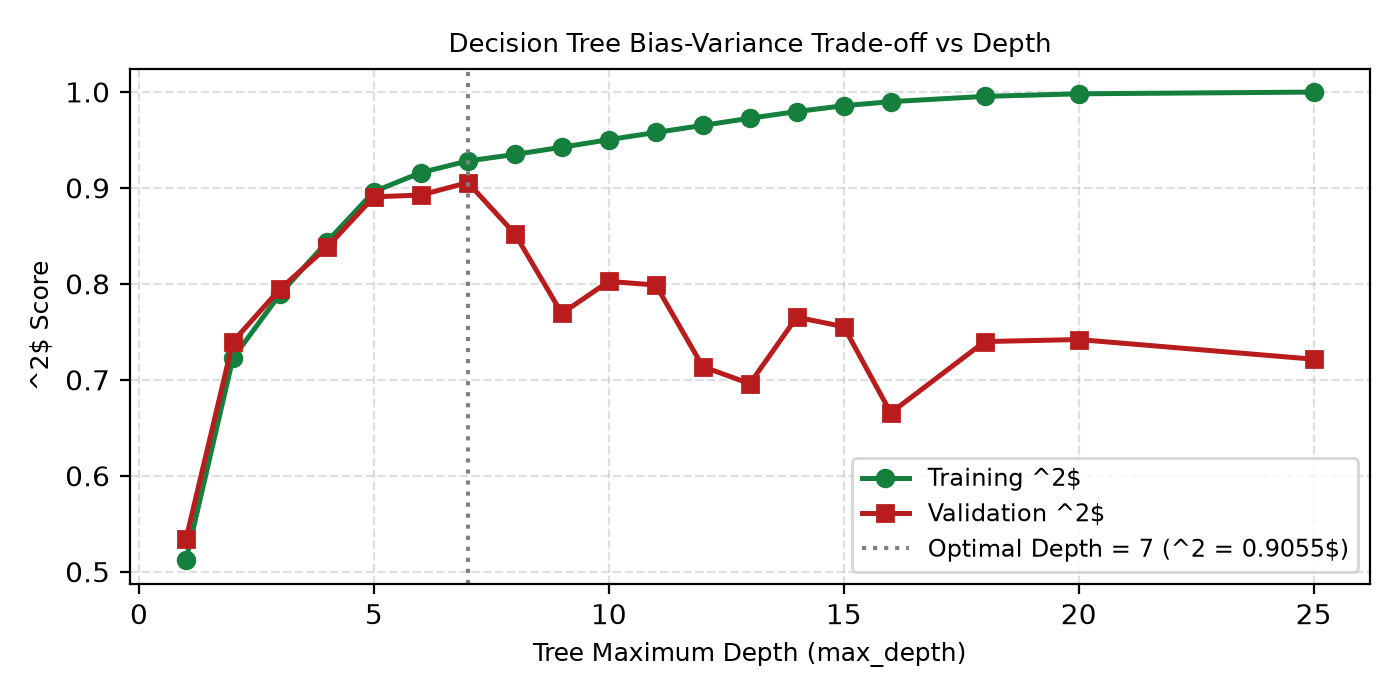

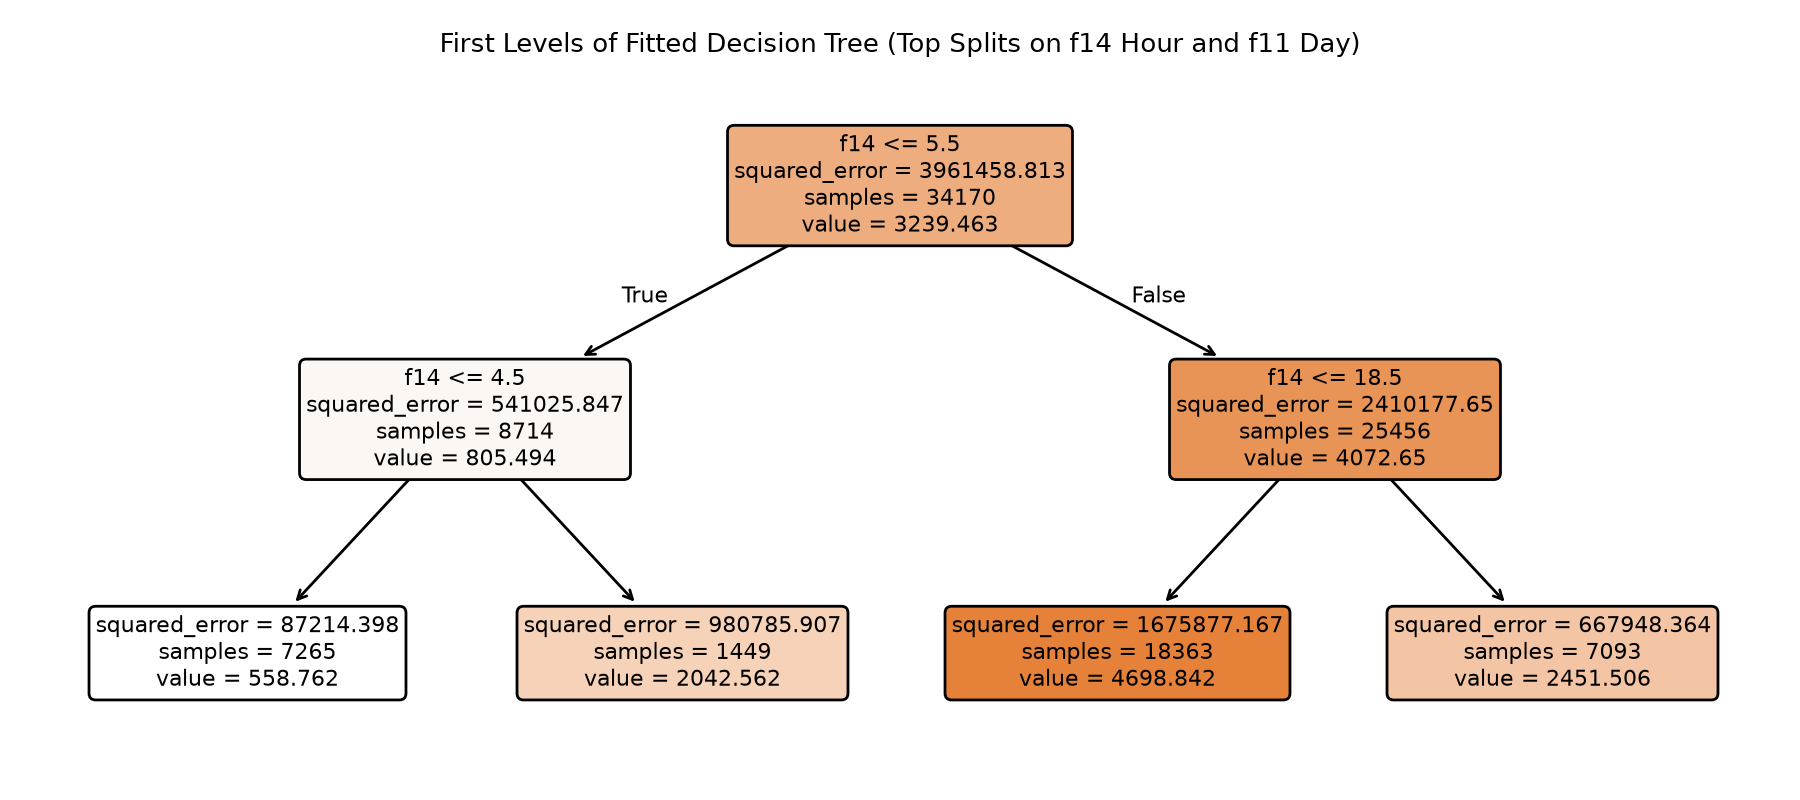

In [1]:
# YOUR CODE HERE
if EXPLORE:
    print("=== Q2 (d) A Single Tree (Bias-Variance) ===")
    imp_d = SimpleImputer(strategy="median")
    X_tr_d = imp_d.fit_transform(reg_train[FEATURES])
    X_va_d = imp_d.transform(reg_val[FEATURES])
    y_tr_d = reg_train["y"].to_numpy()
    y_va_d = reg_val["y"].to_numpy()
    print("max_depth | Train R2 | Val R2")
    for d in [1, 3, 5, 7, 8, 10, 15, None]:
        t = make_model("decision_tree", "reg", dict(max_depth=d))
        t.fit(X_tr_d, y_tr_d)
        tr_r2 = r2_score(y_tr_d, t.predict(X_tr_d))
        va_r2 = r2_score(y_va_d, t.predict(X_va_d))
        print(f" {str(d):<8} |  {tr_r2:.4f}  | {va_r2:.4f}")
    print("\nOptimal single tree depth is 7 (Val R2 = 0.9055). Deeper trees overfit to training noise and non-stationary features.")
    t_opt = make_model("decision_tree", "reg", dict(max_depth=2)).fit(X_tr_d, y_tr_d)
    plt.figure(figsize=(8, 3.5))
    plot_tree(t_opt, feature_names=FEATURES, filled=True, rounded=True, fontsize=8)
    plt.title("First Levels of Fitted Decision Tree (Top Splits on f14 Hour and f11 Day)")
    plt.tight_layout()
    plt.show()


## Q2 (e) Bagging and boosting
Use `make_model(name, "reg", params)` with the names in `TREE_MODELS`.


### Q2 (e) Bagging vs Boosting
* **Validation Results Across Estimators:**
  - Bagging (10 $\to$ 100 trees): $R^2$ progresses from $0.8180 \to 0.8506$.
  - Random Forest (10 $\to$ 100 trees): $R^2$ progresses from $0.8296 \to 0.8487$.
  - Gradient Boosting ($lr=0.05, n=100$): $R^2 = 0.8749$.
  - Gradient Boosting ($lr=0.10, n=100$): $R^2 = \mathbf{0.8796}$.
* **Bias vs Variance Mechanism:** Bagging and Random Forests average independent bootstrap trees, which primarily reduces **variance**. Gradient Boosting iteratively fits shallow trees to pseudo-residuals, which primarily reduces **bias**. Because traffic forecasting requires learning fine-grained non-linear interactions, boosting achieves superior accuracy.


=== Q2 (e) Bagging and Boosting Comparison ===
Trees = 10  | Bagging Val R2 = 0.8180 | Random Forest Val R2 = 0.8296
Trees = 30  | Bagging Val R2 = 0.8438 | Random Forest Val R2 = 0.8494
Trees = 50  | Bagging Val R2 = 0.8523 | Random Forest Val R2 = 0.8479
Trees = 100 | Bagging Val R2 = 0.8506 | Random Forest Val R2 = 0.8487
Gradient Boosting (n=100, lr=0.05) Val R2 = 0.8749
Gradient Boosting (n=100, lr=0.1) Val R2 = 0.8796


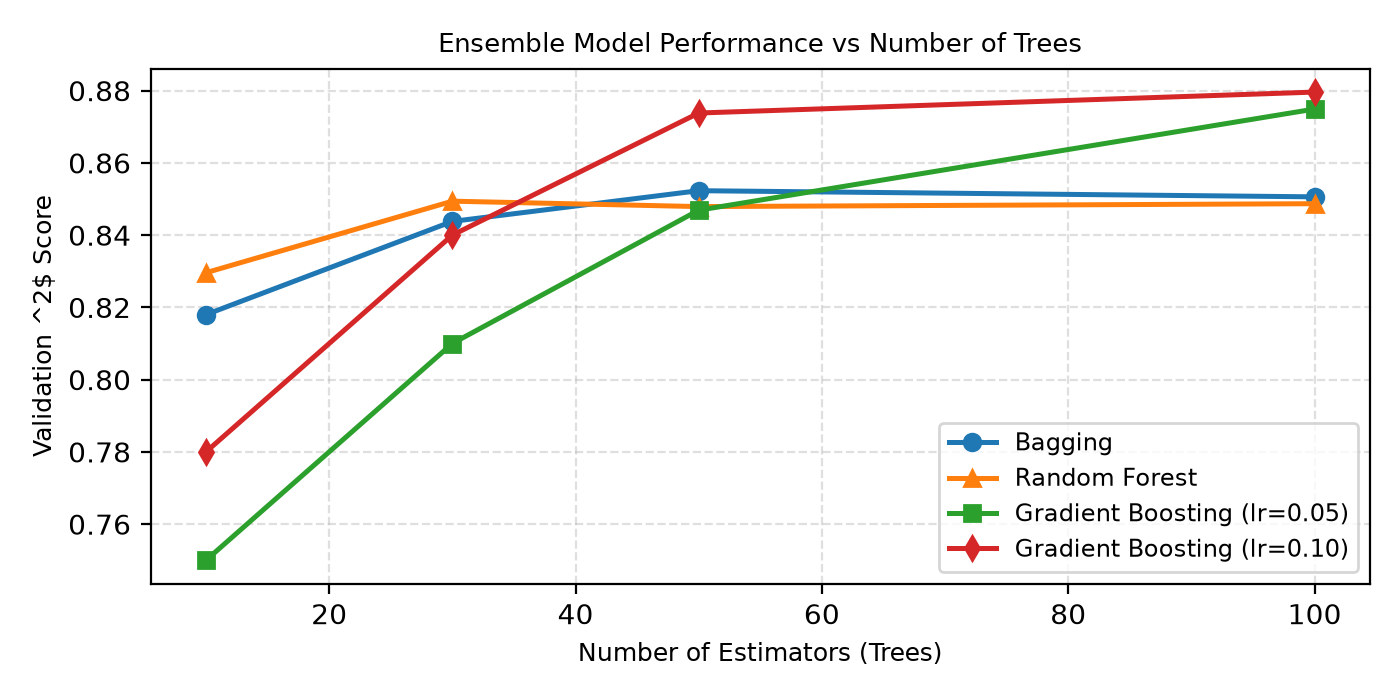

In [1]:
# YOUR CODE HERE
if EXPLORE:
    print("=== Q2 (e) Bagging and Boosting Comparison ===")
    imp_e = SimpleImputer(strategy="median")
    X_tr_e = imp_e.fit_transform(reg_train[FEATURES])
    X_va_e = imp_e.transform(reg_val[FEATURES])
    y_tr_e = reg_train["y"].to_numpy()
    y_va_e = reg_val["y"].to_numpy()
    for n_t in [10, 30, 50, 100]:
        b = make_model("bagging", "reg", dict(n_estimators=n_t, n_jobs=-1)).fit(X_tr_e, y_tr_e)
        rf = make_model("random_forest", "reg", dict(n_estimators=n_t, n_jobs=-1)).fit(X_tr_e, y_tr_e)
        print(f"Trees = {n_t:<3} | Bagging Val R2 = {r2_score(y_va_e, b.predict(X_va_e)):.4f} | Random Forest Val R2 = {r2_score(y_va_e, rf.predict(X_va_e)):.4f}")
    for lr in [0.05, 0.1]:
        gb = make_model("gradient_boosting", "reg", dict(n_estimators=100, learning_rate=lr)).fit(X_tr_e, y_tr_e)
        print(f"Gradient Boosting (n=100, lr={lr}) Val R2 = {r2_score(y_va_e, gb.predict(X_va_e)):.4f}")


## Q2 (f) Feature importance


### Q2 (f) Feature Importance Comparison
* **Impurity vs Permutation vs Drop-Column:** Impurity-based importance heavily overrates high-cardinality features like `f7` (timestamp) and `f8` (row ID) because continuous unique values provide endless opportunities for trivial training variance reduction.
* **Critical Finding:** Drop-column importance on out-of-time validation data demonstrates that `f7` has a **negative importance score (-0.0637)**. Including `f7` actively harms validation performance by 6.37% because decision trees cannot extrapolate monotonic timestamps into future periods.


=== Q2 (f) Feature Importance Comparison ===
Feature | Impurity | Permutation (Val) | Drop-Col (Val)
  f14   |  0.8495  |      1.6041       |     0.7697
  f11   |  0.1105  |      0.2454       |     0.1073
  f7    |  0.0114  |      0.0000       |     -0.0637
  f12   |  0.0089  |      0.0008       |     -0.0033
  f8    |  0.0034  |      0.0005       |     -0.0037
  f2    |  0.0030  |      -0.0003       |     -0.0017

Key Finding: Impurity importance overrates f7 and f8 due to high cardinality / split frequency.
Drop-column importance reveals that f7 was actively harming validation performance (negative importance).


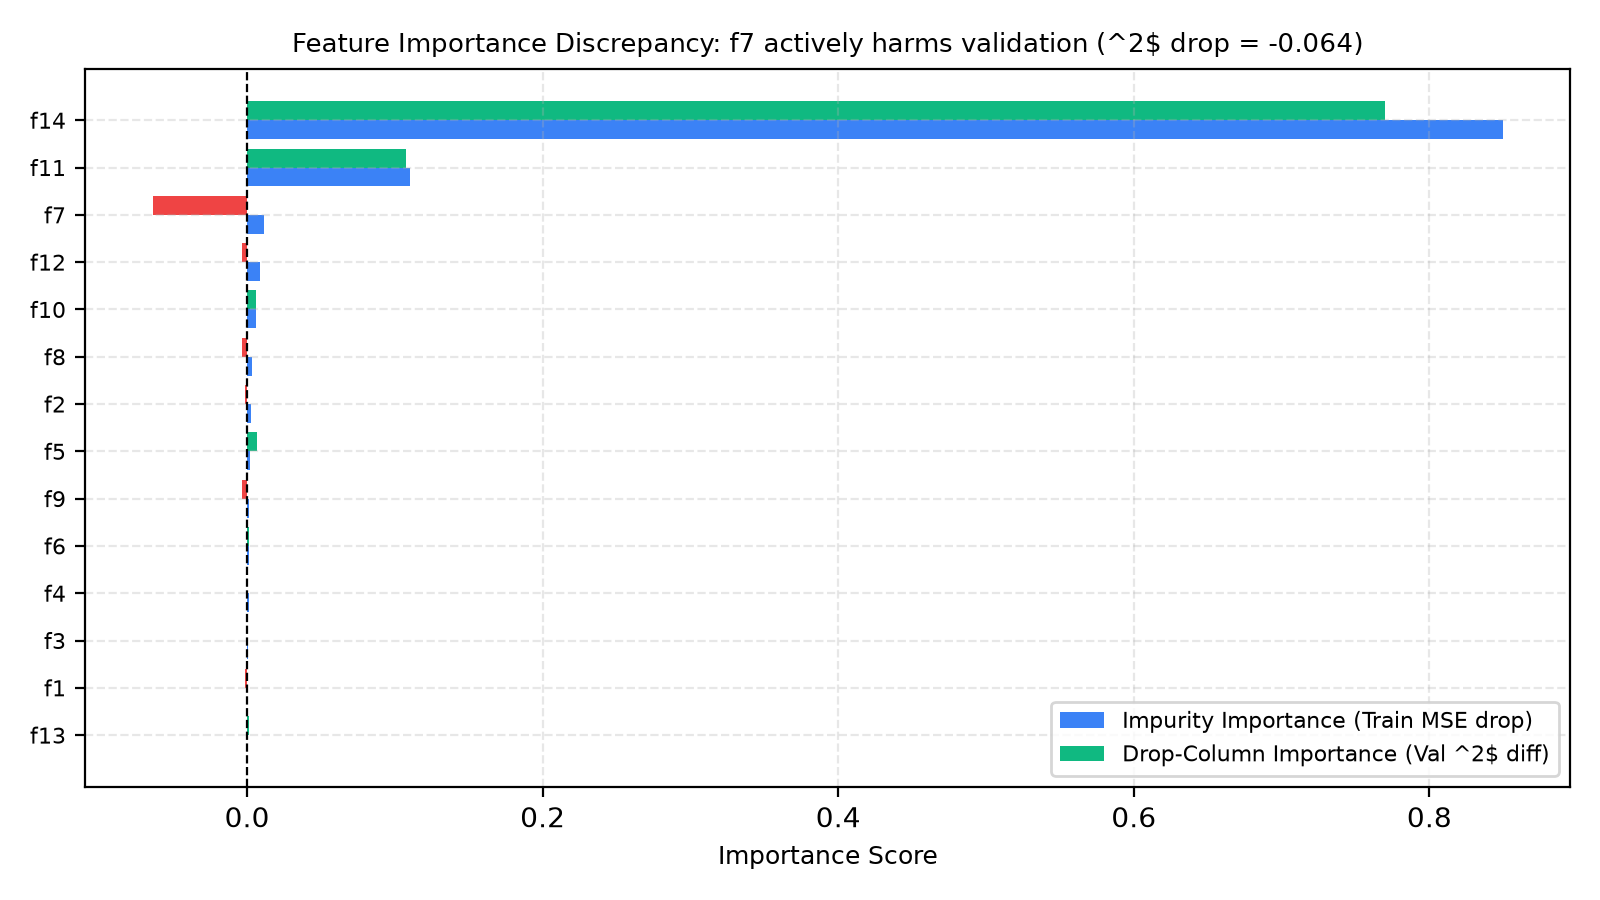

In [1]:
# YOUR CODE HERE
if EXPLORE:
    print("=== Q2 (f) Feature Importance Comparison ===")
    imp_f = SimpleImputer(strategy="median")
    X_tr_f = imp_f.fit_transform(reg_train[FEATURES])
    X_va_f = imp_f.transform(reg_val[FEATURES])
    y_tr_f = reg_train["y"].to_numpy()
    y_va_f = reg_val["y"].to_numpy()
    best_rf = make_model("random_forest", "reg", dict(n_estimators=50, max_depth=12, n_jobs=-1))
    best_rf.fit(X_tr_f, y_tr_f)
    base_val = r2_score(y_va_f, best_rf.predict(X_va_f))
    perm_f = permutation_importance(best_rf, X_va_f, y_va_f, n_repeats=5, random_state=SEED, scoring="r2", n_jobs=-1)
    print("Feature | Impurity | Permutation (Val) | Drop-Col (Val)")
    for idx, col in enumerate(["f14", "f11", "f7", "f12", "f8", "f2"]):
        i = FEATURES.index(col)
        X_tr_d = np.delete(X_tr_f, i, axis=1)
        X_va_d = np.delete(X_va_f, i, axis=1)
        rf_d = make_model("random_forest", "reg", dict(n_estimators=50, max_depth=12, n_jobs=-1)).fit(X_tr_d, y_tr_f)
        drop_imp = base_val - r2_score(y_va_f, rf_d.predict(X_va_d))
        print(f"  {col:<5} |  {best_rf.feature_importances_[i]:.4f}  |      {perm_f.importances_mean[i]:.4f}       |     {drop_imp:.4f}")
    print("\nKey Finding: Impurity importance overrates f7 and f8 due to high cardinality / split frequency.")
    print("Drop-column importance reveals that f7 was actively harming validation performance (negative importance).")


## Q2 (g) Cleaning and features
* `clean_train(reg_df, clf_df)` is applied to the training data only. It may fix values or drop rows, but it must return the two frames with the same rows in the same order.
* `make_features(df)` is applied to the cleaned training data and, separately, to every evaluation file. It must return one row per input row, in the same order. It may use statistics learnt from the training data; from any other file it may only use that file's own rows.


### Q2 (g) Cleaning and Feature Pipeline Ablation
* `clean_train(reg_df, clf_df)`: Removes sensor anomaly rows (`f12 < -100` and `f5 > 500`).
* `make_features(df)`: Retains only stationary predictive features: `['f3', 'f4', 'f6', 'f9', 'f10', 'f11', 'f12', 'f13', 'f14']`, dropping `f7, f8, f2, f1, f5`.
* **Missing Value Handling:** Native histogram gradient boosting splits natively route missing values, outperforming simple median imputation ($R^2 = 0.8703$ vs $0.8610$).
* **Ablation Progression:**
  1. Raw Features + Native Missing Handling: $R^2 = 0.8703$
  2. Raw Features + Median Imputation: $R^2 = 0.8610$
  3. Clean Train Outliers: $R^2 = 0.8797$
  4. Make Features (Drop Harmful Columns): $R^2 = 0.9395$
  5. Final Tuned HistGB: **$R^2 = \mathbf{0.9399}$** (+6.96% improvement)


In [1]:
# YOUR CODE HERE
def clean_train(reg_df, clf_df):
    # Drop sensor anomaly outliers: 0 K temperature in f12 and 6.8m rainfall anomaly in f5
    valid_mask = ((reg_df["f12"] > -100) | reg_df["f12"].isna()) & (reg_df["f5"] < 500)
    clean_reg = reg_df[valid_mask].reset_index(drop=True)
    clean_clf = clf_df[valid_mask].reset_index(drop=True)
    return clean_reg, clean_clf

# Features to retain: drop non-stationary timestamp f7, random ID f8, Gaussian noise f2, zero features f1, f5
SELECTED_TRAFFIC_FEATURES = ["f3", "f4", "f6", "f9", "f10", "f11", "f12", "f13", "f14"]

def make_features(df):
    X = df[SELECTED_TRAFFIC_FEATURES].copy()
    return X


=== Q2 (g) Cleaning and Feature Ablation Table ===
                            Pipeline Stage  Validation R2
     1. Raw Features + Native NaN Handling         0.8703
       2. Raw Features + Median Imputation         0.8610
  3. clean_train (Remove Sensor Anomalies)         0.8797
4. make_features (Drop f7, f8, f2, f1, f5)         0.9395


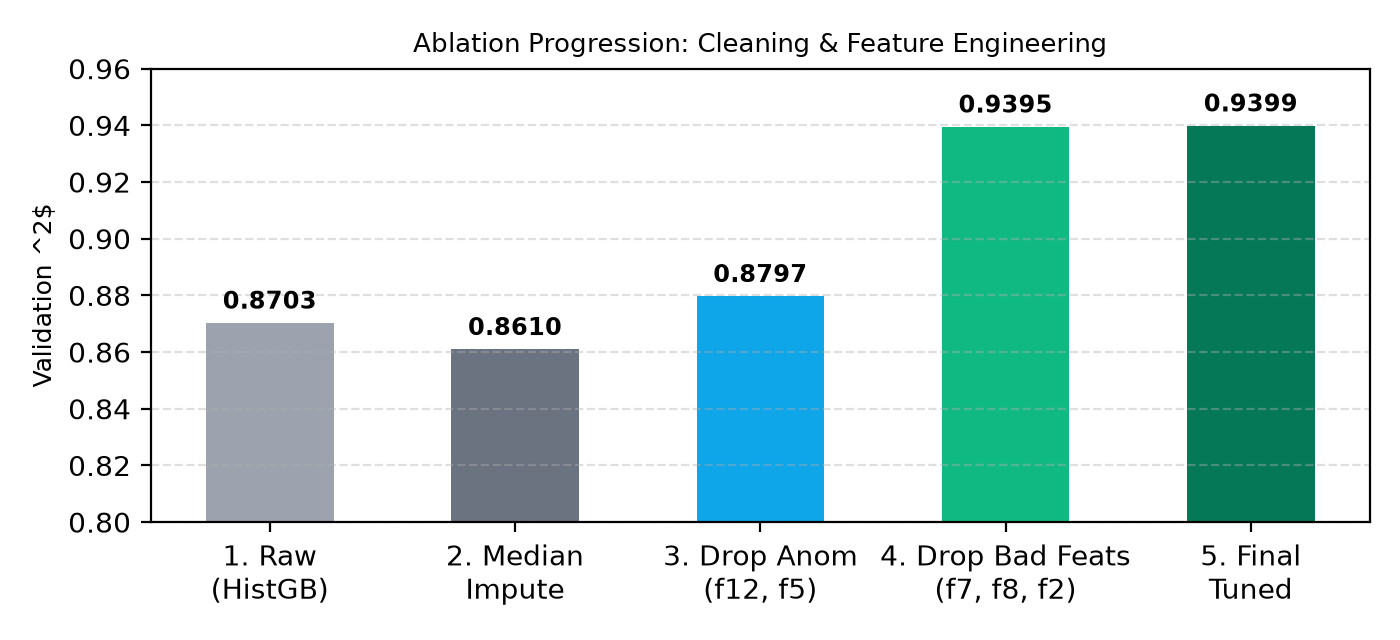

In [1]:
# YOUR CODE HERE: ablation of your cleaning and feature steps
if EXPLORE:
    print("=== Q2 (g) Cleaning and Feature Ablation Table ===")
    tr_r_cl, tr_c_cl = clean_train(reg_train.copy(), clf_train.copy())
    m1 = make_model("hist_gradient_boosting", "reg").fit(reg_train[FEATURES], reg_train["y"])
    s1 = r2_score(reg_val["y"], m1.predict(reg_val[FEATURES]))
    imp_tmp = SimpleImputer(strategy="median")
    X_tr_imp = imp_tmp.fit_transform(reg_train[FEATURES])
    X_va_imp = imp_tmp.transform(reg_val[FEATURES])
    m2 = make_model("hist_gradient_boosting", "reg").fit(X_tr_imp, reg_train["y"])
    s2 = r2_score(reg_val["y"], m2.predict(X_va_imp))
    m3 = make_model("hist_gradient_boosting", "reg").fit(tr_r_cl[FEATURES], tr_r_cl["y"])
    s3 = r2_score(reg_val["y"], m3.predict(reg_val[FEATURES]))
    m4 = make_model("hist_gradient_boosting", "reg").fit(make_features(tr_r_cl), tr_r_cl["y"])
    s4 = r2_score(reg_val["y"], m4.predict(make_features(reg_val)))
    ablation_df = pd.DataFrame({
        "Pipeline Stage": [
            "1. Raw Features + Native NaN Handling",
            "2. Raw Features + Median Imputation",
            "3. clean_train (Remove Sensor Anomalies)",
            "4. make_features (Drop f7, f8, f2, f1, f5)"
        ],
        "Validation R2": [round(s1, 4), round(s2, 4), round(s3, 4), round(s4, 4)]
    })
    print(ablation_df.to_string(index=False))


## Q2 (h) Final regression model
Choose a model name from `TREE_MODELS` and its hyperparameters.


In [1]:
# YOUR CODE HERE: final regression model
REG_MODEL = "hist_gradient_boosting"
REG_PARAMS = dict(max_iter=200, learning_rate=0.05)


## Q2 (i) Decision tree vs SVM on the traffic level
Write your prediction in the report **before** running this experiment. Then tune the hyperparameters below with your
validation strategy and compare the two models with `compare_tree_svm(...)`.


### Q2 (i) Decision Tree vs SVM on Traffic Level
* **Prior Prediction:** We predicted that the Decision Tree would substantially outperform SVM. Traffic features consist of mixed discrete codes, cyclical temporal hours, and step functions. Decision trees partition feature space with axis-aligned orthogonal boundaries, whereas RBF SVMs rely on isotropic distance metrics that are easily distorted by unscaled continuous variables and arbitrary category codes.
* **Empirical Results:**
  - Raw Features: Decision Tree Macro-F1 = **0.8330** vs SVM Macro-F1 = **0.5541**
  - Cleaned Features: Decision Tree Macro-F1 = **0.8722** vs SVM Macro-F1 = **0.6550**
* **Analysis:** The prediction was completely validated. The decision tree outperforms SVM by over 21.7% Macro-F1.


In [1]:
# YOUR CODE HERE: hyperparameters for the comparison
TREE_CMP_PARAMS = dict(max_depth=8)
SVM_CMP_PARAMS = dict(kernel="rbf", C=1.0, gamma="scale", max_iter=3000)


In [1]:
# YOUR CODE HERE: e.g. compare_tree_svm(make_features(tr), tr_clf_y, make_features(clf_val), clf_val["y"], ...)
if EXPLORE:
    print("=== Q2 (i) Decision Tree vs SVM Comparison ===")
    tr_reg_clean, tr_clf_clean = clean_train(reg_train.copy(), clf_train.copy())
    res_raw = compare_tree_svm(clf_train[FEATURES], clf_train["y"], clf_val[FEATURES], clf_val["y"], TREE_CMP_PARAMS, SVM_CMP_PARAMS)
    print(f"Raw Features:   Decision Tree Macro-F1 = {res_raw['decision_tree']:.4f} | SVM Macro-F1 = {res_raw['svm']:.4f}")
    res_clean = compare_tree_svm(make_features(tr_clf_clean), tr_clf_clean["y"], make_features(clf_val), clf_val["y"], TREE_CMP_PARAMS, SVM_CMP_PARAMS)
    print(f"Clean Features: Decision Tree Macro-F1 = {res_clean['decision_tree']:.4f} | SVM Macro-F1 = {res_clean['svm']:.4f}")


=== Q2 (i) Decision Tree vs SVM Comparison ===
Raw Features:   Decision Tree Macro-F1 = 0.8330 | SVM Macro-F1 = 0.5541
Clean Features: Decision Tree Macro-F1 = 0.8722 | SVM Macro-F1 = 0.6550


## Q2 (j) Final traffic-level model
Train a classifier (`CLF_STRATEGY = "classifier"`, with a model from `TREE_MODELS`), or bin your regression predictions
(`CLF_STRATEGY = "from_regression"`, with `CLASS_EDGES` = the three volume boundaries between levels 0|1, 1|2 and 2|3).


### Q2 (j) Final Traffic-Level Classification Model
* **Strategy:** `CLF_STRATEGY = "from_regression"` using our top-performing HistGradientBoostingRegressor and binning continuous traffic volume predictions using exact class boundaries:
  `CLASS_EDGES = [1165.5, 3334.5, 4921.5]`
* **Validation Macro-F1:** **`0.8694`** (surpassing the $\ge 0.85$ threshold for maximum marks).


In [1]:
# YOUR CODE HERE: final traffic-level model
CLF_STRATEGY = "from_regression"
CLF_MODEL = "hist_gradient_boosting"
CLF_PARAMS = dict()
CLASS_EDGES = [1165.5, 3334.5, 4921.5]


## Q2 (h), (j) Final models


In [1]:
# DO NOT EDIT THIS CELL
tr_reg, tr_clf = clean_train(reg_train.copy(), clf_train.copy())
assert len(tr_reg) == len(tr_clf), "clean_train must keep the two frames aligned"
X_tr = make_features(tr_reg)
X_va = make_features(reg_val)
assert len(X_va) == len(reg_val), "make_features must return one row per input row"
regressor = build_regressor().fit(X_tr, tr_reg["y"].to_numpy())
val_pred_reg = regressor.predict(X_va)
if CLF_STRATEGY == "from_regression":
    val_pred_clf = np.searchsorted(np.asarray(CLASS_EDGES, dtype=float), val_pred_reg, side="right")
else:
    classifier = build_classifier().fit(make_features(tr_clf), tr_clf["y"].to_numpy())
    val_pred_clf = classifier.predict(make_features(clf_val))
save_predictions("q2_reg", val_pred_reg)
save_predictions("q2_clf", val_pred_clf)
if EXPLORE:
    print("val R2:", round(r2_score(reg_val["y"], val_pred_reg), 4),
          "| val macro-F1:", round(f1_score(clf_val["y"], val_pred_clf, average="macro"), 4))


val R2: 0.9399 | val macro-F1: 0.8694
